# 06_Correlation_Analysis — Relationships & Dependencies

In [1]:
import os
if 'notebooks' in os.getcwd():
    os.chdir('..')
print(f'Working directory: {os.getcwd()}')

Working directory: D:\Data analyst\Portfolio\project-1-refugee-integration


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
sns.set_style('whitegrid')
print('✓ Libraries loaded')

✓ Libraries loaded


In [3]:
master = pd.read_parquet('data/processed/refugee_master_consolidated.parquet')
print(f'Data shape: {master.shape}')

Data shape: (29506, 27)


## 1. Component Correlation Matrix

In [4]:
components = ['employment_rate', 'housing_access', 'education_enrollment', 'income_stability', 'legal_rights_score', 'social_cohesion', 'integration_index']

corr_matrix = master[components].corr(method='pearson')
print('Pearson Correlation Matrix:')
print(corr_matrix.round(3))

Pearson Correlation Matrix:
                      employment_rate  housing_access  education_enrollment  \
employment_rate                 1.000           0.157                 0.062   
housing_access                  0.157           1.000                 0.036   
education_enrollment            0.062           0.036                 1.000   
income_stability                0.149           0.098                 0.104   
legal_rights_score              0.145           0.127                 0.127   
social_cohesion                 0.096           0.022                 0.064   
integration_index               0.635           0.459                 0.417   

                      income_stability  legal_rights_score  social_cohesion  \
employment_rate                  0.149               0.145            0.096   
housing_access                   0.098               0.127            0.022   
education_enrollment             0.104               0.127            0.064   
income_stability       

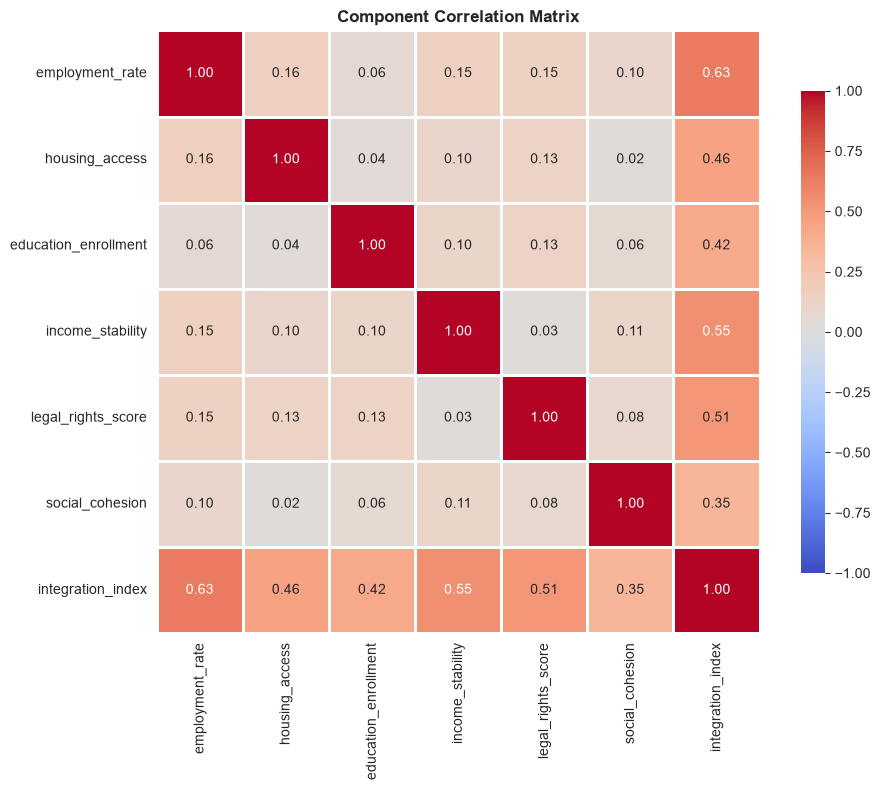

✓ Saved: 06_correlation_matrix.png


In [5]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, 
            square=True, linewidths=1, cbar_kws={"shrink": 0.8}, ax=ax, vmin=-1, vmax=1)
ax.set_title('Component Correlation Matrix', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('output/06_correlation_matrix.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 06_correlation_matrix.png')

## 2. Correlation with Integration Index

In [6]:
component_list = ['employment_rate', 'housing_access', 'education_enrollment', 'income_stability', 'legal_rights_score', 'social_cohesion']

correlations = []
for comp in component_list:
    pearson_corr, p_value = pearsonr(master[comp], master['integration_index'])
    correlations.append({
        'Component': comp,
        'Pearson r': pearson_corr,
        'P-value': p_value,
        'Significant': 'Yes' if p_value < 0.05 else 'No'
    })

corr_df = pd.DataFrame(correlations).sort_values('Pearson r', ascending=False)
print(corr_df.to_string(index=False))

           Component  Pearson r  P-value Significant
     employment_rate   0.634536      0.0         Yes
    income_stability   0.553795      0.0         Yes
  legal_rights_score   0.508569      0.0         Yes
      housing_access   0.458569      0.0         Yes
education_enrollment   0.417456      0.0         Yes
     social_cohesion   0.346866      0.0         Yes


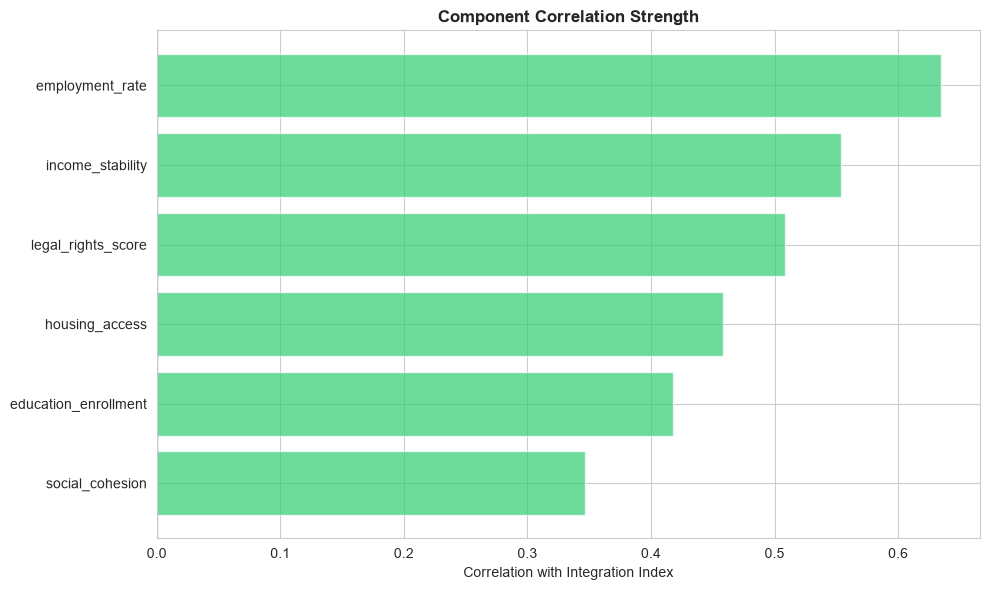

✓ Saved: 06_component_correlations.png


In [7]:
fig, ax = plt.subplots(figsize=(10, 6))
corr_df_sorted = corr_df.sort_values('Pearson r')
colors = ['#2ecc71' if x >= 0 else '#e74c3c' for x in corr_df_sorted['Pearson r']]
ax.barh(corr_df_sorted['Component'], corr_df_sorted['Pearson r'], color=colors, alpha=0.7)
ax.set_xlabel('Correlation with Integration Index')
ax.set_title('Component Correlation Strength', fontsize=12, fontweight='bold')
ax.axvline(x=0, color='black', linestyle='-', linewidth=0.8)
plt.tight_layout()
plt.savefig('output/06_component_correlations.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 06_component_correlations.png')

## 3. Pairwise Component Relationships

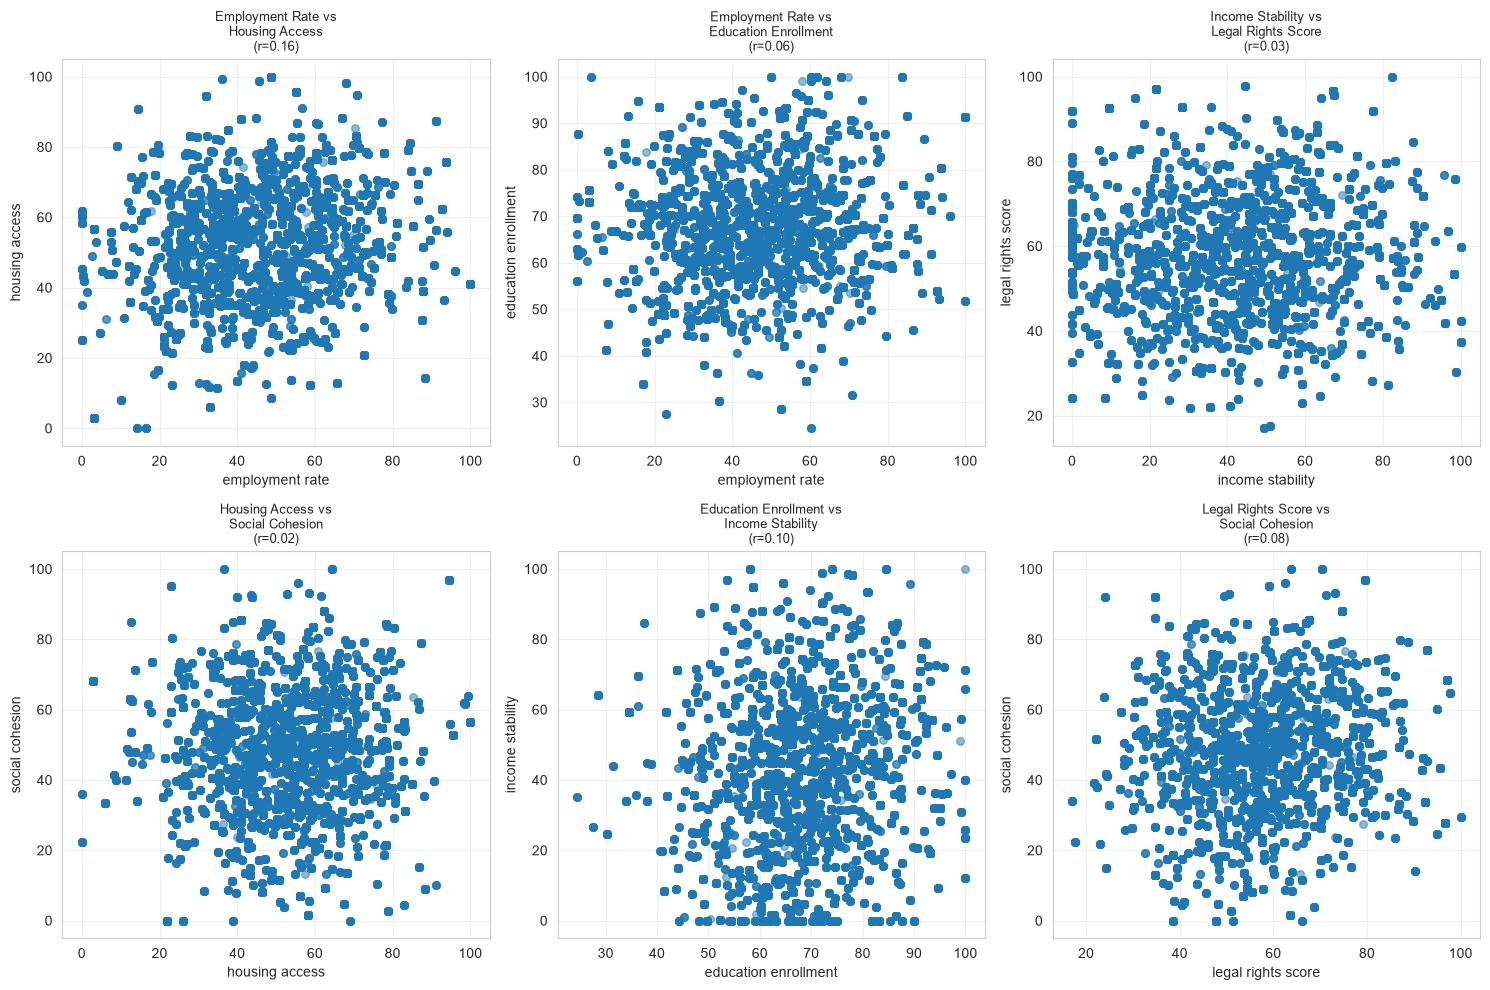

✓ Saved: 06_pairwise_relationships.png


In [8]:
# Employment vs Housing
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()

pairs = [
    ('employment_rate', 'housing_access'),
    ('employment_rate', 'education_enrollment'),
    ('income_stability', 'legal_rights_score'),
    ('housing_access', 'social_cohesion'),
    ('education_enrollment', 'income_stability'),
    ('legal_rights_score', 'social_cohesion')
]

for i, (x, y) in enumerate(pairs):
    axes[i].scatter(master[x], master[y], alpha=0.5, s=30)
    r, _ = pearsonr(master[x], master[y])
    axes[i].set_title(f'{x.replace("_", " ").title()} vs\n{y.replace("_", " ").title()}\n(r={r:.2f})', fontsize=9)
    axes[i].set_xlabel(x.replace('_', ' '))
    axes[i].set_ylabel(y.replace('_', ' '))
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('output/06_pairwise_relationships.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 06_pairwise_relationships.png')

## 4. Refugee Volume Correlations

In [9]:
# Does higher refugee volume correlate with lower integration?
r_refugees, p_refugees = pearsonr(master['Refugees under UNHCR\'s mandate'], master['integration_index'])
r_asylum, p_asylum = pearsonr(master['Asylum-seekers'], master['integration_index'])

print(f'Refugees vs Integration Index: r={r_refugees:.3f}, p={p_refugees:.4f}')
print(f'Asylum-seekers vs Integration Index: r={r_asylum:.3f}, p={p_asylum:.4f}')

Refugees vs Integration Index: r=0.001, p=0.9174
Asylum-seekers vs Integration Index: r=0.040, p=0.0000


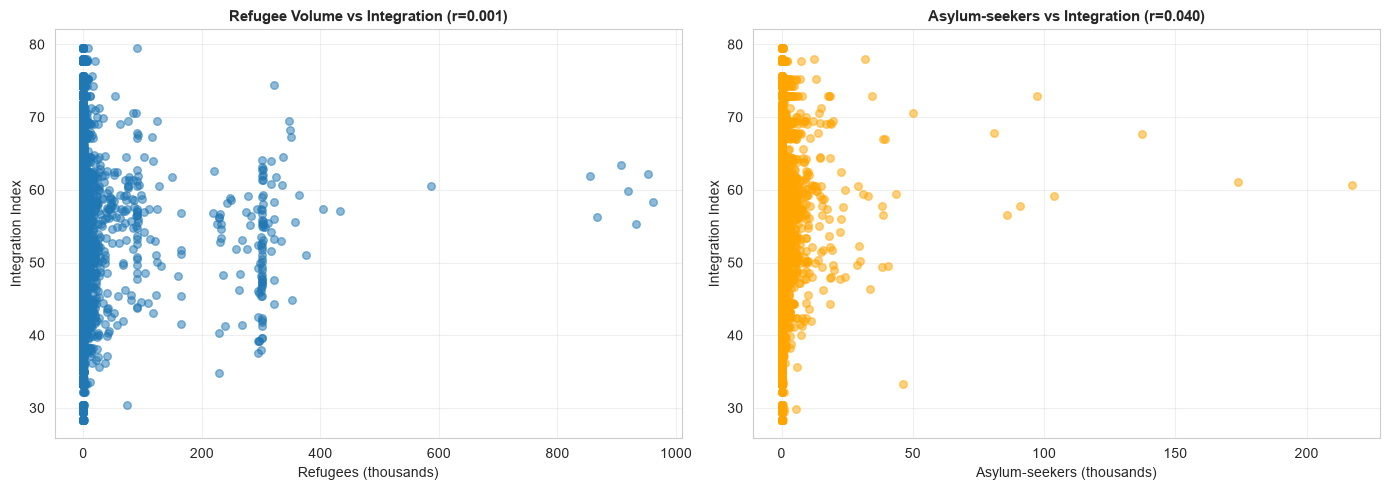

✓ Saved: 06_volume_correlations.png


In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.scatter(master['Refugees under UNHCR\'s mandate'] / 1000, master['integration_index'], alpha=0.5, s=30)
ax1.set_xlabel('Refugees (thousands)')
ax1.set_ylabel('Integration Index')
ax1.set_title(f'Refugee Volume vs Integration (r={r_refugees:.3f})', fontsize=11, fontweight='bold')
ax1.grid(True, alpha=0.3)

ax2.scatter(master['Asylum-seekers'] / 1000, master['integration_index'], alpha=0.5, s=30, color='orange')
ax2.set_xlabel('Asylum-seekers (thousands)')
ax2.set_ylabel('Integration Index')
ax2.set_title(f'Asylum-seekers vs Integration (r={r_asylum:.3f})', fontsize=11, fontweight='bold')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('output/06_volume_correlations.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 06_volume_correlations.png')

## 5. Summary Statistics Table

In [11]:
summary = pd.DataFrame({
    'Relationship': ['Refugees vs Index', 'Asylum-seekers vs Index'],
    'Pearson r': [r_refugees, r_asylum],
    'P-value': [p_refugees, p_asylum],
    'Significant': ['Yes' if p_refugees < 0.05 else 'No', 'Yes' if p_asylum < 0.05 else 'No'],
    'Interpretation': [
        'Weak positive' if r_refugees > 0 else 'Weak negative',
        'Weak positive' if r_asylum > 0 else 'Weak negative'
    ]
})
print(summary.round(4).to_string(index=False))

           Relationship  Pearson r  P-value Significant Interpretation
      Refugees vs Index     0.0006   0.9174          No  Weak positive
Asylum-seekers vs Index     0.0397   0.0000         Yes  Weak positive
